1. loaded the dataset.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("titanic/train.csv")
print(df.head())
df.info()
print(df.describe())
print(df.isnull().sum())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  
<c

2. handele the missing data.

In [2]:
print("Mean Age:", df["Age"].mean())
print("Median Age:", df["Age"].median())

Mean Age: 29.69911764705882
Median Age: 28.0


In [3]:
df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df.drop(columns=["Cabin"])

print(df.isnull().sum())

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


3. encode Categorical Variables

3a. Label Encoding: Sex

In [4]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

le = LabelEncoder()
df["Sex"] = le.fit_transform(df["Sex"])

print(df["Sex"].value_counts())
print(le.classes_)

Sex
1    577
0    314
Name: count, dtype: int64
['female' 'male']


3b. One-Hot Encoding: Embarked

In [5]:
ohe = OneHotEncoder(sparse_output=False)
embarked_encoded = ohe.fit_transform(df[["Embarked"]])

embarked_df = pd.DataFrame(
    embarked_encoded,
    columns=ohe.get_feature_names_out(["Embarked"]),
    index=df.index
)

df = pd.concat([df.drop(columns=["Embarked"]), embarked_df], axis=1)
print(df.head())

   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name  Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris    1  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...    0  38.0      1      0   
2                             Heikkinen, Miss. Laina    0  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)    0  35.0      1      0   
4                           Allen, Mr. William Henry    1  35.0      0      0   

             Ticket     Fare  Embarked_C  Embarked_Q  Embarked_S  
0         A/5 21171   7.2500         0.0         0.0         1.0  
1          PC 17599  71.2833         1.0         0.0         0.0  
2  STON/O2. 3101282   7.9250         0.0         0.0         1.0  
3            113803  53.1000

4. visualize Age Distribution

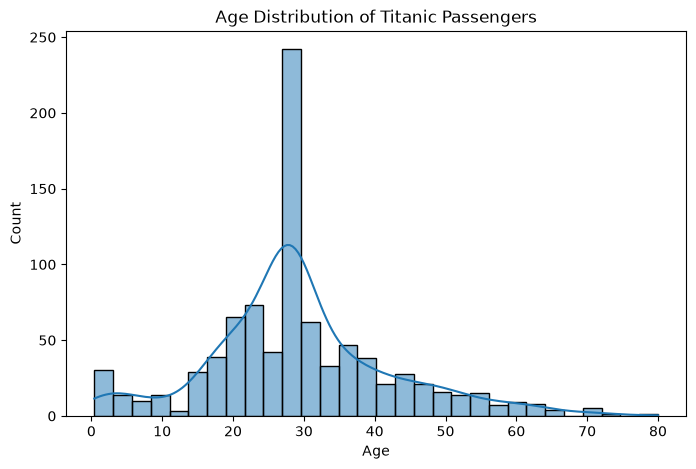

In [6]:
plt.figure(figsize=(8, 5))
sns.histplot(df["Age"], bins=30, kde=True)
plt.title("Age Distribution of Titanic Passengers")
plt.xlabel("Age")
plt.ylabel("Count")
plt.show()

5. Output Cleaned Dataset as CSV

In [7]:
df.to_csv("titanic_cleaned.csv", index=False)

# quick check
check = pd.read_csv("titanic_cleaned.csv")
print(check.shape)
print(check.isnull().sum().sum())
print(check.head())

(891, 13)
0
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name  Sex   Age  SibSp  Parch  \
0                            Braund, Mr. Owen Harris    1  22.0      1      0   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...    0  38.0      1      0   
2                             Heikkinen, Miss. Laina    0  26.0      0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)    0  35.0      1      0   
4                           Allen, Mr. William Henry    1  35.0      0      0   

             Ticket     Fare  Embarked_C  Embarked_Q  Embarked_S  
0         A/5 21171   7.2500         0.0         0.0         1.0  
1          PC 17599  71.2833         1.0         0.0         0.0  
2  STON/O2. 3101282   7.9250         0.0         0.0         1.0  
3            113